In [1]:
!pip install -q -U kaggle
!pip install -q transformers timm pycocotools torchmetrics ultralytics appdirs

In [19]:
# libraries
import os, re, json, glob, time, random, shutil, zipfile, copy

import numpy as np
import pandas as pd
from PIL import Image
import matplotlib.pyplot as plt
from tqdm.auto import tqdm
import subprocess

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torch.optim import AdamW
from torch.utils.flop_counter import FlopCounterMode

from transformers import DetrForObjectDetection, DetrImageProcessor
from ultralytics import YOLO, RTDETR

from torchmetrics.detection import MeanAveragePrecision

from google.colab import userdata, drive

import transformers, torchmetrics, ultralytics
print("torch:", torch.__version__)
print("transformers:", transformers.__version__)
print("ultralytics:", ultralytics.__version__)
print("torchmetrics:", torchmetrics.__version__)
print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "None")
transformers.logging.set_verbosity_error()

torch: 2.11.0+cu130
transformers: 5.20.2
ultralytics: 8.4.188
torchmetrics: 1.9.0
GPU: Tesla T4


In [24]:
drive.mount('/content/drive')

PROJECT_DIR = "/content/drive/MyDrive/cmpe_249_project_fog"
CKPT_DIR    = f"{PROJECT_DIR}/checkpoints"
RESULTS_DIR = f"{PROJECT_DIR}/results"
for d in (PROJECT_DIR, CKPT_DIR, RESULTS_DIR):
    os.makedirs(d, exist_ok=True)

DATA_ROOT   = "/content/data"
FOGGY_DIR   = f"{DATA_ROOT}/foggy_cityscapes"
ANN_DIR     = f"{DATA_ROOT}/cityscapes"

SEED = 1

def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.benchmark = False

def seed_worker(worker_id):
    s = torch.initial_seed() % 2**32
    np.random.seed(s)
    random.seed(s)

def make_generator(seed=SEED):
    g = torch.Generator()
    g.manual_seed(seed)
    return g

set_seed()

assert torch.cuda.is_available(), "No GPU: Runtime > Change runtime type > T4 GPU"
device = torch.device("cuda")

BETAS = [0.005, 0.01, 0.02]     # the three densities in Foggy Cityscapes
BETA_MAX = max(BETAS)           # used later to normalize beta to (0, 1]
NUM_CLASSES = 8                 # confirm in the data cell (we'll print the class names)

CFG = dict(
    seed=SEED,
    epochs=3,
    batch_size=4,               # T4 (16 GB); we may lower this for DETR with AMP off
    num_workers=2,
    amp=True,                   # mixed precision; saves memory/time on the T4
    film_lr=1e-3,               # FiLM params get their own, higher LR
    backbone_lr=1e-5,
    head_lr=1e-4,
)
print("Config:", CFG)
print("Project dir:", PROJECT_DIR)

Config: {'seed': 1, 'epochs': 3, 'batch_size': 4, 'num_workers': 2, 'amp': True, 'film_lr': 0.001, 'backbone_lr': 1e-05, 'head_lr': 0.0001}
Project dir: /content/drive/MyDrive/cmpe_249_project_fog


**dataset**

In [10]:
# ---------- settings ----------
USE_SCENES = "all"       # "all" = 2975 train + 500 val scenes | "refined" = 550-scene subset
DELETE_ZIP = True        # frees ~29 GB once images are extracted
MIN_BOX_PX = 4           # the dataset cell drops boxes with w<4 or h<4 (22 of 69,720)

# Verified against the files' own `classes` key. Id 8 = "cantsolve" is dropped.
CLASS_NAMES  = ["person", "rider", "car", "truck", "bus", "train", "motorcycle", "bicycle"]
CANTSOLVE_ID = 8
assert len(CLASS_NAMES) == NUM_CLASSES

RAW_DIR     = "/content/raw"
FOGGY_ZIP   = f"{RAW_DIR}/foggy-cityscapes.zip"
CS_ZIP      = f"{RAW_DIR}/gtBboxValidated_trainval.zip"
REFINED_TXT = f"{PROJECT_DIR}/foggy_trainval_refined_filenames.txt"   # kept on Drive; the zip gets deleted
for d in (RAW_DIR, FOGGY_DIR, ANN_DIR):
    os.makedirs(d, exist_ok=True)

EXPECTED_IMAGES = {"all": 3 * (2975 + 500), "refined": 3 * 550}[USE_SCENES]

def list_foggy():
    return glob.glob(f"{FOGGY_DIR}/leftImg8bit_foggy/*/*/*.png")

# ---------- A) foggy images ----------
if len(list_foggy()) == EXPECTED_IMAGES:
    print("Foggy images already extracted.")
else:
    os.environ["KAGGLE_API_TOKEN"] = userdata.get("KAGGLE_API_TOKEN")
    if not os.path.exists(FOGGY_ZIP):
        !kaggle datasets download -d minhducnguyen9705/foggy-cityscapes -p {RAW_DIR}

    with zipfile.ZipFile(FOGGY_ZIP) as z:
        refined_text = z.read("foggy_trainval_refined_filenames.txt").decode()
        with open(REFINED_TXT, "w") as f:
            f.write(refined_text)
        refined = set(refined_text.splitlines())          # "split/city/scene"

        selected = []
        for n in z.namelist():
            parts = n.split("/")                          # leftImg8bit_foggy / split / city / file
            if len(parts) != 4 or not n.endswith(".png") or parts[0] != "leftImg8bit_foggy":
                continue
            _, split, city, fn = parts
            if split not in ("train", "val"):             # test labels are not public
                continue
            scene = fn.split("_leftImg8bit_foggy_")[0]
            if USE_SCENES == "refined" and f"{split}/{city}/{scene}" not in refined:
                continue
            selected.append(n)

        todo = [n for n in selected if not os.path.exists(f"{FOGGY_DIR}/{n}")]
        print(f"Selected {len(selected)} images, extracting {len(todo)}")
        for n in tqdm(todo, desc="Extracting"):
            z.extract(n, FOGGY_DIR)

    assert len(list_foggy()) == EXPECTED_IMAGES, "Image count mismatch after extraction"
    if DELETE_ZIP:
        os.remove(FOGGY_ZIP)

# ---------- B) box annotations ----------
if not glob.glob(f"{ANN_DIR}/gtBboxValidated/*/*/*_gtBboxValidated.json"):
    if not os.path.exists(CS_ZIP):
        if not os.path.isdir("/content/cityscapesScripts"):
            !git clone -q https://github.com/mcordts/cityscapesScripts.git /content/cityscapesScripts
        cs_user = userdata.get("CITYSCAPES_USER")
        answers = f"{cs_user}\n{userdata.get('CITYSCAPES_PASS')}\nN\n"   # username, password, store-credentials=N
        r = subprocess.run(
            ["python", "/content/cityscapesScripts/cityscapesscripts/download/downloader.py",
             "-d", RAW_DIR, "gtBboxValidated_trainval.zip"],
            input=answers, text=True, capture_output=True)
        if not os.path.exists(CS_ZIP):
            print((r.stdout + r.stderr)[-600:].replace(cs_user, "***"))
            raise RuntimeError("Cityscapes download failed (see the scrubbed log above)")
    with zipfile.ZipFile(CS_ZIP) as z:
        z.extractall(ANN_DIR)

# ---------- C) index: one row per image, sorted so the order is identical on every run ----------
with open(REFINED_TXT) as f:
    refined_set = set(f.read().splitlines())

rows = []
for p in list_foggy():
    split, city, fn = p.split("/")[-3:]
    scene = fn.split("_leftImg8bit_foggy_")[0]
    rows.append(dict(
        split=split, city=city, scene=scene,
        beta=float(re.search(r"beta_(0\.\d+)", fn).group(1)),
        img_path=p,
        ann_path=f"{ANN_DIR}/gtBboxValidated/{split}/{city}/{scene}_gtBboxValidated.json",
        refined=f"{split}/{city}/{scene}" in refined_set,
    ))
index_df = (pd.DataFrame(rows)
            .sort_values(["split", "city", "scene", "beta"])
            .reset_index(drop=True))

# ---------- checks ----------
assert len(index_df) == EXPECTED_IMAGES
assert index_df.ann_path.map(os.path.exists).all(), "Some images have no annotation file"
assert sorted(index_df.beta.unique()) == BETAS
assert not (set(index_df[index_df.split == "train"].city) &
            set(index_df[index_df.split == "val"].city)), "Train/val share a city"
index_df.to_csv(f"{RESULTS_DIR}/data_index.csv", index=False)

print("\nImages per split x beta:")
print(index_df.groupby(["split", "beta"]).size().unstack())
print("\nScenes per split:", index_df.groupby("split").scene.nunique().to_dict())
print("Refined scenes per split:", index_df[index_df.refined].groupby("split").scene.nunique().to_dict())
print("Cities per split:", index_df.groupby("split").city.nunique().to_dict())
print(f"Disk free: {shutil.disk_usage('/content').free / 1e9:.0f} GB")

Selected 10425 images, extracting 10425


Extracting:   0%|          | 0/10425 [00:00<?, ?it/s]


Images per split x beta:
beta   0.005  0.010  0.020
split                     
train   2975   2975   2975
val      500    500    500

Scenes per split: {'train': 2975, 'val': 500}
Refined scenes per split: {'train': 498, 'val': 52}
Cities per split: {'train': 18, 'val': 3}
Disk free: 53 GB


In [11]:
# colab space being used
!df -h /content | tail -1
!du -sh /content/data /content/raw /content/cityscapes* /root/.cache 2>/dev/null
print("Foggy zip still present:", os.path.exists(FOGGY_ZIP))   # should be False

overlay         113G   64G   50G  56% /
21G	/content/data
3.2M	/content/raw
12M	/content/cityscapesScripts
60M	/root/.cache
Foggy zip still present: False


In [12]:
# hold out whole cities from train for checkpoint selection
# Roles: "train" = fit | "dev" = pick best epoch / tune | "test" = official Cityscapes val, final numbers only
train_df = index_df[index_df.split == "train"]
city_scenes = train_df.groupby("city").scene.nunique().sort_values(ascending=False)
print("Train cities (scenes per city):")
print(city_scenes.to_string())

N_HOLDOUT_CITIES = 3
HOLDOUT_CITIES = None
if HOLDOUT_CITIES is None:
    rng = random.Random(SEED)    # seeded, so the choice is identical on every run
    HOLDOUT_CITIES = sorted(rng.sample(sorted(city_scenes.index), N_HOLDOUT_CITIES))
print("\nHeld-out cities:", HOLDOUT_CITIES)

index_df["role"] = np.where(index_df.split == "val", "test",
                    np.where(index_df.city.isin(HOLDOUT_CITIES), "dev", "train"))

# ---- checks ----
cities_by_role = {r: set(g.city) for r, g in index_df.groupby("role")}
assert not (cities_by_role["train"] & cities_by_role["dev"])
assert not (cities_by_role["train"] & cities_by_role["test"])
assert not (cities_by_role["dev"] & cities_by_role["test"])
# all 3 betas of a scene must land in the same role
assert (index_df.groupby("scene").role.nunique() == 1).all()

print("\nImages per role x beta:")
print(index_df.groupby(["role", "beta"]).size().unstack())
print("\nScenes per role:", index_df.groupby("role").scene.nunique().to_dict())
index_df.to_csv(f"{RESULTS_DIR}/data_index.csv", index=False)

Train cities (scenes per city):
city
strasbourg         365
bremen             316
hamburg            248
dusseldorf         221
stuttgart          196
hanover            196
aachen             174
cologne            154
tubingen           144
weimar             142
zurich             122
jena               119
erfurt             109
krefeld             99
bochum              96
ulm                 95
monchengladbach     94
darmstadt           85

Held-out cities: ['bremen', 'darmstadt', 'hanover']

Images per role x beta:
beta   0.005  0.010  0.020
role                      
dev      597    597    597
test     500    500    500
train   2378   2378   2378

Scenes per role: {'dev': 597, 'test': 500, 'train': 2378}


Parsing boxes:   0%|          | 0/3475 [00:00<?, ?it/s]

Objects per class x role:
role        train   dev  test
person      14903  3208  3714
rider        1313   553   542
car         22533  6017  4135
truck         342   200    91
bus           304    78   101
train         131    49    23
motorcycle    586   122   150
bicycle      3697  1483  1888

Object size share per role (COCO thresholds, original pixels):
size   large  medium  small
role                       
dev    0.273   0.511  0.217
test   0.269   0.489  0.242
train  0.293   0.497  0.209

Scenes with zero valid boxes: {'dev': 0, 'test': 7, 'train': 10}


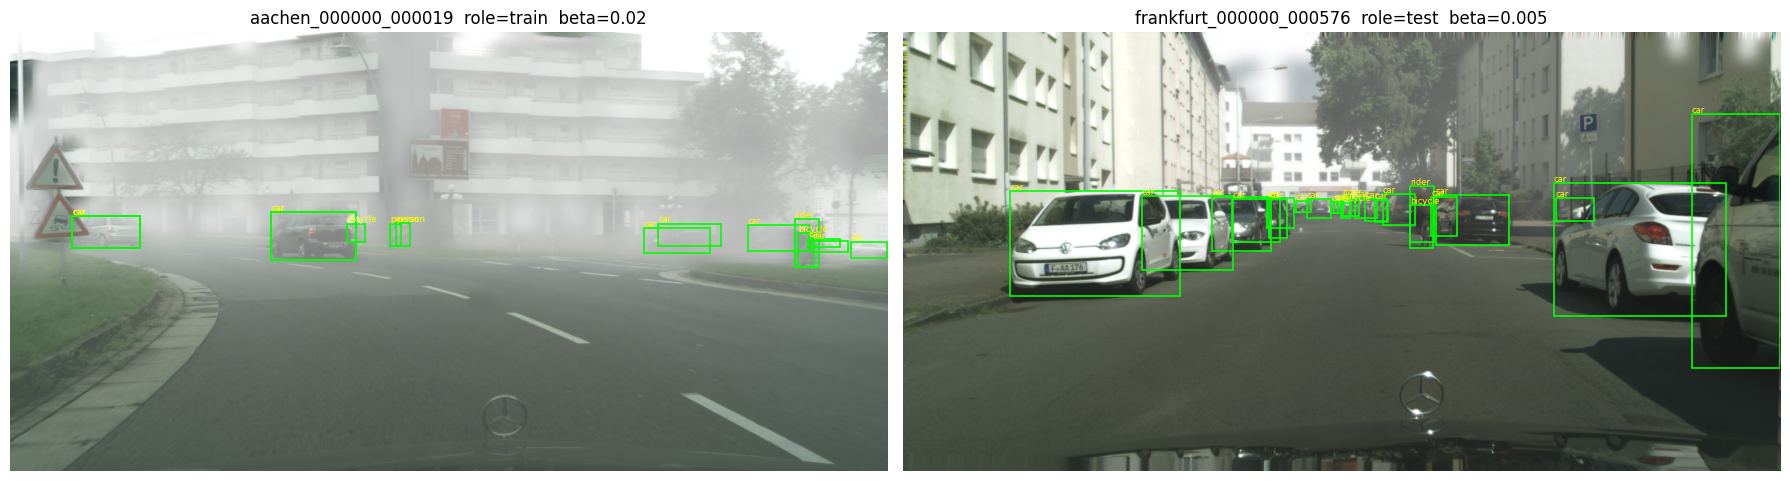

In [13]:
# parse, filter and cache boxes
def load_boxes(ann_path):
    """Boxes as [x1, y1, x2, y2, class] in original 2048x1024 pixels. Drops cantsolve and tiny boxes."""
    with open(ann_path) as f:
        a = json.load(f)
    out = []
    for o in a["objects"]:
        c = int(np.argmax(o["soft_label"]))
        if c == CANTSOLVE_ID:
            continue
        x1, y1, x2, y2 = o["bbox"]
        if (x2 - x1) < MIN_BOX_PX or (y2 - y1) < MIN_BOX_PX:
            continue
        out.append([x1, y1, x2, y2, c])
    return np.array(out, dtype=np.float32).reshape(-1, 5)

# annotations are per scene, shared by the 3 betas, so parse each file once
BOXES = {p: load_boxes(p) for p in tqdm(index_df.ann_path.unique(), desc="Parsing boxes")}
index_df["n_boxes"] = index_df.ann_path.map(lambda p: len(BOXES[p]))

import pickle
with open(f"{RESULTS_DIR}/boxes.pkl", "wb") as f:
    pickle.dump(BOXES, f)

# ---- stats per role ----
scene_df = index_df.drop_duplicates("ann_path")
rows = []
for r in scene_df.itertuples():
    for x1, y1, x2, y2, c in BOXES[r.ann_path]:
        area = (x2 - x1) * (y2 - y1)
        rows.append((r.role, int(c), "small" if area < 32**2 else "medium" if area < 96**2 else "large"))
st = pd.DataFrame(rows, columns=["role", "cls", "size"])

print("Objects per class x role:")
t = st.groupby(["cls", "role"]).size().unstack(fill_value=0)
t.index = [CLASS_NAMES[i] for i in t.index]
print(t[["train", "dev", "test"]])
print("\nObject size share per role (COCO thresholds, original pixels):")
print(st.groupby("role")["size"].value_counts(normalize=True).unstack().round(3))
print("\nScenes with zero valid boxes:", scene_df.groupby("role").n_boxes.apply(lambda s: (s == 0).sum()).to_dict())

# ---- visual check: boxes on two foggy images ----
fig, axes = plt.subplots(1, 2, figsize=(18, 5))
for ax, (role, beta) in zip(axes, [("train", 0.02), ("test", 0.005)]):
    row = index_df[(index_df.role == role) & (index_df.beta == beta) & (index_df.n_boxes >= 15)].iloc[0]
    ax.imshow(Image.open(row.img_path).convert("RGB"))
    for x1, y1, x2, y2, c in BOXES[row.ann_path]:
        ax.add_patch(plt.Rectangle((x1, y1), x2 - x1, y2 - y1, fill=False, edgecolor="lime", linewidth=1.2))
        ax.text(x1, y1 - 3, CLASS_NAMES[int(c)], color="yellow", fontsize=6)
    ax.set_title(f"{row.scene}  role={role}  beta={beta}"); ax.axis("off")
plt.tight_layout(); plt.show()

**detr preprocessing**

In [14]:
n_empty_json = sum(len(json.load(open(p))["objects"]) == 0 for p in scene_df.ann_path)
print(f"Scenes whose JSON has no objects at all: {n_empty_json} | "
      f"scenes with no valid boxes after filtering: {int((scene_df.n_boxes == 0).sum())}")

# ---- beta normalization: log2 scale -> {0.005: 0, 0.01: 0.5, 0.02: 1} ----
def beta_to_norm(beta):
    return float(np.log2(beta / BETAS[0]) / np.log2(BETAS[-1] / BETAS[0]))
BETA_NORM = {b: beta_to_norm(b) for b in BETAS}
print("beta -> normalized:", BETA_NORM)

# ---- processor ----
DETR_SHORT_EDGE, DETR_LONG_EDGE = 800, 1333
processor = DetrImageProcessor.from_pretrained(
    "facebook/detr-resnet-50",
    size={"shortest_edge": DETR_SHORT_EDGE, "longest_edge": DETR_LONG_EDGE})

class DetrFogDataset(Dataset):
    def __init__(self, df, processor):
        self.records = df[["img_path", "ann_path", "beta"]].to_dict("records")
        self.processor = processor

    def __len__(self):
        return len(self.records)

    def __getitem__(self, idx):
        r = self.records[idx]
        image = Image.open(r["img_path"]).convert("RGB")
        anns = [{"bbox": [x1, y1, x2 - x1, y2 - y1], "category_id": int(c),
                 "area": float((x2 - x1) * (y2 - y1)), "iscrowd": 0}
                for x1, y1, x2, y2, c in BOXES[r["ann_path"]]]
        enc = self.processor(images=image,
                             annotations={"image_id": idx, "annotations": anns},
                             return_tensors="pt")
        return {"pixel_values": enc["pixel_values"][0],
                "pixel_mask": enc["pixel_mask"][0],
                "labels": enc["labels"][0],
                "beta": torch.tensor(r["beta"], dtype=torch.float32),
                "beta_norm": torch.tensor(BETA_NORM[r["beta"]], dtype=torch.float32)}

def detr_collate(batch):
    return {"pixel_values": torch.stack([b["pixel_values"] for b in batch]),
            "pixel_mask":   torch.stack([b["pixel_mask"] for b in batch]),
            "labels":       [b["labels"] for b in batch],
            "beta":         torch.stack([b["beta"] for b in batch]),
            "beta_norm":    torch.stack([b["beta_norm"] for b in batch])}

def make_loader(role, shuffle, batch_size=None):
    ds = DetrFogDataset(index_df[index_df.role == role], processor)
    return DataLoader(ds, batch_size=batch_size or CFG["batch_size"], shuffle=shuffle,
                      collate_fn=detr_collate, num_workers=CFG["num_workers"],
                      worker_init_fn=seed_worker, generator=make_generator(), pin_memory=True)

train_loader = make_loader("train", shuffle=True)
dev_loader   = make_loader("dev",   shuffle=False)
test_loader  = make_loader("test",  shuffle=False)
print("Batches (train/dev/test):", len(train_loader), len(dev_loader), len(test_loader))

# ---- tests ----
ds = train_loader.dataset

# normalized cxcywh labels -> original-pixel xyxy must equal the cached boxes
i = next(k for k, r in enumerate(ds.records) if len(BOXES[r["ann_path"]]) > 5)
item = ds[i]
print("\npixel_values:", tuple(item["pixel_values"].shape), "| beta:", item["beta"].item(),
      "| beta_norm:", item["beta_norm"].item())
cx, cy, w, h = item["labels"]["boxes"].unbind(-1)
back = torch.stack([(cx - w/2) * 2048, (cy - h/2) * 1024, (cx + w/2) * 2048, (cy + h/2) * 1024], -1)
ref = torch.tensor(BOXES[ds.records[i]["ann_path"]])
assert back.shape == ref[:, :4].shape, "box count changed in the processor"
assert (item["labels"]["class_labels"] == ref[:, 4].long()).all(), "class labels changed"
print("Box round-trip max error (px):", (back - ref[:, :4]).abs().max().item())
assert (back - ref[:, :4]).abs().max() < 0.5

# a scene with no boxes must not crash the processor
j = next(k for k, r in enumerate(ds.records) if len(BOXES[r["ann_path"]]) == 0)
print("Empty-scene labels boxes shape:", tuple(ds[j]["labels"]["boxes"].shape))

# image loading speed (decides whether num_workers=2 starves the GPU)
t0 = time.time()
for k in range(10):
    _ = ds[k]
print(f"Mean time per item (load + resize + normalize): {(time.time() - t0) / 10 * 1000:.0f} ms")

Scenes whose JSON has no objects at all: 16 | scenes with no valid boxes after filtering: 17
beta -> normalized: {0.005: 0.0, 0.01: 0.5, 0.02: 1.0}


preprocessor_config.json:   0%|          | 0.00/290 [00:00<?, ?B/s]

Batches (train/dev/test): 1784 448 375

pixel_values: (3, 666, 1333) | beta: 0.004999999888241291 | beta_norm: 0.0
Box round-trip max error (px): 0.0
Empty-scene labels boxes shape: (0, 4)
Mean time per item (load + resize + normalize): 102 ms


**evaluation metrics**

In [15]:
SCALAR_KEYS = ["map", "map_50", "map_75", "map_small", "map_medium", "map_large",
               "mar_1", "mar_10", "mar_100", "mar_small", "mar_medium", "mar_large"]

def labels_to_pixel_targets(label):
    """HF DETR label dict (normalized cxcywh) -> original-pixel xyxy target (verified: 0.0 px round-trip)."""
    h, w = label["orig_size"].tolist()
    cx, cy, bw, bh = label["boxes"].unbind(-1)
    boxes = torch.stack([(cx - bw/2) * w, (cy - bh/2) * h, (cx + bw/2) * w, (cy + bh/2) * h], -1)
    return {"boxes": boxes.float().cpu(), "labels": label["class_labels"].long().cpu()}

def _scalars(res):
    return {k: float(res[k]) for k in SCALAR_KEYS}

class DetectionEvaluator:
    """preds/targets: lists of dicts with xyxy boxes in ORIGINAL pixels (preds also scores, labels)."""
    def __init__(self):
        self.m_all = MeanAveragePrecision(box_format="xyxy", iou_type="bbox", class_metrics=True)
        self.m_beta = {b: MeanAveragePrecision(box_format="xyxy", iou_type="bbox") for b in BETAS}
        self.n_gt = np.zeros(NUM_CLASSES, dtype=int)

    def update(self, preds, targets, betas):
        self.m_all.update(preds, targets)
        for t in targets:
            self.n_gt += np.bincount(t["labels"].numpy(), minlength=NUM_CLASSES)
        for b in BETAS:
            sel = [i for i, x in enumerate(betas) if abs(x - b) < 1e-6]
            if sel:
                self.m_beta[b].update([preds[i] for i in sel], [targets[i] for i in sel])

    def compute(self):
        res = self.m_all.compute()
        per_class = pd.DataFrame({
            "class": [CLASS_NAMES[int(c)] for c in res["classes"]],
            "AP": res["map_per_class"].numpy(),
            "AR_100": res["mar_100_per_class"].numpy(),
        })
        per_class["n_gt"] = [self.n_gt[CLASS_NAMES.index(c)] for c in per_class["class"]]
        per_beta = pd.DataFrame({b: _scalars(m.compute()) for b, m in self.m_beta.items()
                                 if m._update_count > 0}).T
        per_beta.index.name = "beta"
        return {"overall": _scalars(res), "per_class": per_class, "per_beta": per_beta}

# self test
def eval_selftest(loader, n_batches=20):
    gts, betas = [], []
    for k, batch in enumerate(loader):
        if k == n_batches:
            break
        gts += [labels_to_pixel_targets(l) for l in batch["labels"]]
        betas += batch["beta"].tolist()

    def perfect(t):  return {"boxes": t["boxes"], "scores": torch.ones(len(t["boxes"])), "labels": t["labels"]}
    def shifted(t):  return {"boxes": t["boxes"] + torch.tensor([4., 0., 4., 0.]),
                             "scores": torch.ones(len(t["boxes"])), "labels": t["labels"]}
    def wrongcls(t): return {"boxes": t["boxes"], "scores": torch.ones(len(t["boxes"])),
                             "labels": (t["labels"] + 1) % NUM_CLASSES}
    def empty(t):    return {"boxes": torch.zeros(0, 4), "scores": torch.zeros(0), "labels": torch.zeros(0, dtype=torch.long)}

    rows = {}
    for name, fn in [("perfect", perfect), ("shifted 4px", shifted), ("wrong class", wrongcls), ("no predictions", empty)]:
        ev = DetectionEvaluator()
        ev.update([fn(t) for t in gts], gts, betas)
        rows[name] = ev.compute()["overall"]
    out = pd.DataFrame(rows).T[["map", "map_50", "map_75", "map_small", "map_medium", "map_large", "mar_100"]]
    print(f"Self-test on {len(gts)} images, no model involved:")
    print(out.round(3))
    assert out.loc["perfect", "map"] > 0.99
    assert out.loc["perfect", "map"] > out.loc["shifted 4px", "map"] > 0.02
    assert out.loc["shifted 4px", "map_50"] > out.loc["shifted 4px", "map_75"] - 1e-6
    assert out.loc["wrong class", "map"] < 0.01 and out.loc["no predictions", "map"] < 0.01
    print("Evaluator self-test passed.")

eval_selftest(test_loader)

Self-test on 80 images, no model involved:
                  map  map_50  map_75  map_small  map_medium  map_large  \
perfect         1.000    1.00   1.000      1.000       1.000      1.000   
shifted 4px     0.735    0.96   0.799      0.253       0.723      0.934   
wrong class     0.000    0.00   0.000      0.000       0.000      0.000   
no predictions  0.000    0.00   0.000      0.000       0.000      0.000   

                mar_100  
perfect           1.000  
shifted 4px       0.788  
wrong class       0.000  
no predictions    0.000  
Evaluator self-test passed.


In [16]:
# DETR builder, optimizer groups, resumable training loop
def build_detr_baseline():
    set_seed()                                   # identical initialization every time
    model = DetrForObjectDetection.from_pretrained(
        "facebook/detr-resnet-50", num_labels=NUM_CLASSES, ignore_mismatched_sizes=True)
    return model.to(device)

def make_optimizer(model):
    """Three learning-rate groups: FiLM (new, high LR) / backbone (low) / everything else (transformer + heads)."""
    groups = {"film": [], "backbone": [], "head": []}
    for n, p in model.named_parameters():
        if p.requires_grad:
            groups["film" if "film" in n else "backbone" if "backbone" in n else "head"].append(p)
    lrs = {"film": CFG["film_lr"], "backbone": CFG["backbone_lr"], "head": CFG["head_lr"]}
    pg = [{"params": v, "lr": lrs[k]} for k, v in groups.items() if v]
    for k, v in groups.items():
        if v:
            print(f"  {k:9s} lr={lrs[k]:.0e}  params={sum(p.numel() for p in v):,}")
    return AdamW(pg, weight_decay=1e-4)

def forward_loss(model, batch, use_beta):
    if use_beta:                                  # FiLM models read beta from the backbone wrapper
        model.model.backbone.beta = batch["beta_norm"].to(device)
    labels = [{k: v.to(device) for k, v in t.items()} for t in batch["labels"]]
    with torch.autocast("cuda", dtype=torch.float16, enabled=CFG["amp"]):
        out = model(pixel_values=batch["pixel_values"].to(device, non_blocking=True),
                    pixel_mask=batch["pixel_mask"].to(device, non_blocking=True),
                    labels=labels)
    return out.loss

def train_step(model, batch, optimizer, scaler, use_beta):
    loss = forward_loss(model, batch, use_beta)
    optimizer.zero_grad(set_to_none=True)
    if not torch.isfinite(loss):
        return None                               # skip (and count) non-finite losses
    scaler.scale(loss).backward()
    scaler.unscale_(optimizer)
    torch.nn.utils.clip_grad_norm_(model.parameters(), 0.1)   # DETR's standard clipping
    scaler.step(optimizer); scaler.update()
    return loss.item()

@torch.no_grad()
def dev_loss(model, loader, use_beta, max_steps=None):
    model.eval(); tot, n = 0.0, 0
    for i, batch in enumerate(tqdm(loader, desc="dev", leave=False)):
        if max_steps and i >= max_steps:
            break
        tot += forward_loss(model, batch, use_beta).item(); n += 1
    return tot / max(n, 1)

def fit(name, model, epochs, use_beta=False):
    """Resumable: re-running after a disconnect continues from the last finished epoch."""
    tr_loader, dv_loader = make_loader("train", True), make_loader("dev", False)  # fresh seeded loaders
    optimizer = make_optimizer(model)
    scaler = torch.amp.GradScaler("cuda", enabled=CFG["amp"])
    last, best = f"{CKPT_DIR}/{name}_last.pt", f"{CKPT_DIR}/{name}_best.pt"
    state = dict(epoch=0, best_dev=float("inf"), history=[])
    if os.path.exists(last):
        ck = torch.load(last, map_location=device, weights_only=False)
        model.load_state_dict(ck["model"]); optimizer.load_state_dict(ck["optimizer"])
        scaler.load_state_dict(ck["scaler"]); state = ck["state"]
        print(f"Resumed {name} after epoch {state['epoch']}")
    for epoch in range(state["epoch"], epochs):
        t0 = time.time(); model.train(); tot, n, skipped = 0.0, 0, 0
        for batch in tqdm(tr_loader, desc=f"{name} epoch {epoch+1}/{epochs}", leave=False):
            l = train_step(model, batch, optimizer, scaler, use_beta)
            if l is None: skipped += 1
            else: tot += l; n += 1
        dv = dev_loss(model, dv_loader, use_beta)
        state["epoch"] = epoch + 1
        state["history"].append(dict(epoch=epoch + 1, train_loss=tot / max(n, 1), dev_loss=dv,
                                     skipped_steps=skipped, minutes=(time.time() - t0) / 60))
        if dv < state["best_dev"]:
            state["best_dev"] = dv
            torch.save(model.state_dict(), best)
        torch.save(dict(model=model.state_dict(), optimizer=optimizer.state_dict(),
                        scaler=scaler.state_dict(), state=state), last)
        print(state["history"][-1])
    pd.DataFrame(state["history"]).to_csv(f"{RESULTS_DIR}/{name}_history.csv", index=False)
    return state

config.json:   0%|          | 0.00/4.59k [00:00<?, ?B/s]

[transformers] You passed `num_labels=8` which is incompatible to the `id2label` map of length `91`.


model.safetensors: reconstructing file:   0%|          |  0.00B /  167MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/530 [00:00<?, ?it/s]

[transformers] DetrForObjectDetection LOAD REPORT from: facebook/detr-resnet-50
Key                                                            | Status     |                                                                                        
---------------------------------------------------------------+------------+----------------------------------------------------------------------------------------
model.backbone.model.layer4.0.downsample.1.num_batches_tracked | UNEXPECTED |                                                                                        
model.backbone.model.layer3.0.downsample.1.num_batches_tracked | UNEXPECTED |                                                                                        
model.backbone.model.layer2.0.downsample.1.num_batches_tracked | UNEXPECTED |                                                                                        
model.backbone.model.layer1.0.downsample.1.num_batches_tracked | UNEXPECTED |             

  backbone  lr=1e-05  params=23,454,912
  head      lr=1e-04  params=18,048,525


dev:   0%|          | 0/448 [00:00<?, ?it/s]


Per train step: data wait 0.00s + compute 0.60s = 0.60s
Per dev step (includes loader startup): 0.94s | peak GPU memory: 5.6 GB
Non-finite losses in 28 steps: 0
Estimated 1 epoch: train 18 min + dev 7 min = 25 min
  3 epochs: 1.2 h
  5 epochs: 2.1 h
  10 epochs: 4.1 h


**model**
- base
- detr + film

**base & eval**

In [21]:
#DETR -> evaluator adapter
def decode_detr(logits, pred_boxes, label_dicts):
    """DETR outputs -> list of {boxes (xyxy, original px), scores, labels}, one per image."""
    probs = logits.float().softmax(-1)[..., :-1]          # drop the no-object class
    scores, labels = probs.max(-1)
    cx, cy, w, h = pred_boxes.float().unbind(-1)
    preds = []
    for i, lab in enumerate(label_dicts):
        H, W = lab["orig_size"].tolist()
        boxes = torch.stack([(cx[i] - w[i]/2) * W, (cy[i] - h[i]/2) * H,
                             (cx[i] + w[i]/2) * W, (cy[i] + h[i]/2) * H], -1)
        preds.append({"boxes": boxes.cpu(), "scores": scores[i].cpu(), "labels": labels[i].cpu()})
    return preds

@torch.no_grad()
def evaluate_detr(model, loader, use_beta, max_batches=None):
    model.eval()
    ev = DetectionEvaluator()
    for k, batch in enumerate(tqdm(loader, desc="evaluating", leave=False)):
        if max_batches and k == max_batches:
            break
        if use_beta:
            model.model.backbone.beta = batch["beta_norm"].to(device)
        with torch.autocast("cuda", dtype=torch.float16, enabled=CFG["amp"]):
            out = model(pixel_values=batch["pixel_values"].to(device),
                        pixel_mask=batch["pixel_mask"].to(device))
        preds = decode_detr(out.logits, out.pred_boxes, batch["labels"])
        targets = [labels_to_pixel_targets(l) for l in batch["labels"]]
        ev.update(preds, targets, batch["beta"].tolist())
    return ev.compute()

# # ---- test 1: decode path with a synthetic "perfect" DETR (no model involved) ----
# batch = next(iter(test_loader))
# B, Q = len(batch["labels"]), 100
# logits = torch.full((B, Q, NUM_CLASSES + 1), -20.0); logits[..., -1] = 20.0      # everything = no-object
# boxes = torch.tensor([0.5, 0.5, 0.1, 0.1]).repeat(B, Q, 1)
# targets = []
# for i, lab in enumerate(batch["labels"]):
#     n = min(len(lab["class_labels"]), Q)                  # DETR has only 100 queries
#     logits[i, :n, -1] = -20.0
#     logits[i, torch.arange(n), lab["class_labels"][:n]] = 20.0
#     boxes[i, :n] = lab["boxes"][:n]
#     t = labels_to_pixel_targets(lab)
#     targets.append({"boxes": t["boxes"][:n], "labels": t["labels"][:n]})
# ev = DetectionEvaluator()
# ev.update(decode_detr(logits, boxes, batch["labels"]), targets, batch["beta"].tolist())
# print("Synthetic perfect DETR -> mAP:", round(ev.compute()["overall"]["map"], 4), "(must be ~1.0)")
# assert ev.compute()["overall"]["map"] > 0.99

# # ---- test 2: end to end on an UNTRAINED model: tables must populate, mAP must be ~0 ----
# untrained = build_detr_baseline()
# res = evaluate_detr(untrained, test_loader, use_beta=False, max_batches=6)
# print("\nUntrained DETR, 6 test batches (24 images): mAP", round(res["overall"]["map"], 4))
# print("\nper_beta:\n", res["per_beta"][["map", "map_50", "mar_100"]].round(4))
# print("\nper_class:\n", res["per_class"].round(4))
# del untrained; torch.cuda.empty_cache()

Synthetic perfect DETR -> mAP: 1.0 (must be ~1.0)


Loading weights:   0%|          | 0/530 [00:00<?, ?it/s]

evaluating:   0%|          | 0/375 [00:00<?, ?it/s]


Untrained DETR, 6 test batches (24 images): mAP 0.0009

per_beta:
           map  map_50  mar_100
beta                          
0.005  0.0008  0.0025   0.0737
0.010  0.0009  0.0027   0.0824
0.020  0.0011  0.0035   0.0684

per_class:
         class      AP  AR_100  n_gt
0      person  0.0000  0.0000   108
1       rider  0.0000  0.0000    15
2         car  0.0029  0.0348   330
3       truck  0.0016  0.4000     6
4         bus -1.0000 -1.0000     0
5       train -1.0000 -1.0000     0
6  motorcycle  0.0000  0.0000     3
7     bicycle  0.0007  0.0143    21


In [23]:
#baseline training
assert CFG["epochs"] is not None, "Set epochs in the CFG cell (cell 3) first"
print(f"DETR baseline: {CFG['epochs']} epochs, batch {CFG['batch_size']}, "
      f"{DETR_SHORT_EDGE}/{DETR_LONG_EDGE}, seed {SEED}, AMP {CFG['amp']}")

detr_base = build_detr_baseline()
state = fit("detr_baseline", detr_base, epochs=CFG["epochs"], use_beta=False)

hist = pd.DataFrame(state["history"])
print(hist.round(4).to_string(index=False))
print(f"\nBest dev loss {state['best_dev']:.4f} at epoch {int(hist.loc[hist.dev_loss.idxmin(), 'epoch'])}")
print("Total skipped (non-finite) steps:", int(hist.skipped_steps.sum()))

plt.figure(figsize=(6, 3.5))
plt.plot(hist.epoch, hist.train_loss, marker="o", label="train")
plt.plot(hist.epoch, hist.dev_loss, marker="o", label="dev")
plt.xlabel("epoch"); plt.ylabel("loss"); plt.legend(); plt.title("DETR baseline"); plt.show()

DETR baseline: 5 epochs, batch 4, 800/1333, seed 1, AMP True


Loading weights:   0%|          | 0/530 [00:00<?, ?it/s]

  backbone  lr=1e-05  params=23,454,912
  head      lr=1e-04  params=18,048,525


detr_baseline epoch 1/5:   0%|          | 0/1784 [00:00<?, ?it/s]

dev:   0%|          | 0/448 [00:00<?, ?it/s]

...

detr_baseline epoch 3/5:   0%|          | 0/1784 [00:00<?, ?it/s]

dev:   0%|          | 0/448 [00:00<?, ?it/s]

{'epoch': 3, 'train_loss': 1.6432922305748068, 'dev_loss': 1.7149904077606541, 'skipped_steps': 0, 'minutes': 22.60959521532059}


detr_baseline epoch 4/5:   0%|          | 0/1784 [00:00<?, ?it/s]

KeyboardInterrupt: 

In [28]:
# test-set evaluation helpers + DETR baseline on the official val set
SWAP = {0.0: 1.0, 0.5: 0.0, 1.0: 0.5}        # every beta mapped to a WRONG beta (for the ablation)

def _beta_for_mode(b, mode):
    if mode == "true":
        return b
    if mode == "swapped":
        return torch.tensor([SWAP[round(float(x), 3)] for x in b], dtype=b.dtype)
    if mode == "constant":
        return torch.full_like(b, 0.5)
    raise ValueError(mode)

@torch.no_grad()
def evaluate_detr_mode(model, loader, beta_mode=None):
    """beta_mode=None for models without fog input; otherwise 'true' | 'swapped' | 'constant'."""
    model.eval()
    ev = DetectionEvaluator()
    for batch in tqdm(loader, desc=f"evaluating ({beta_mode})", leave=False):
        if beta_mode is not None:
            model.model.backbone.beta = _beta_for_mode(batch["beta_norm"], beta_mode).to(device)
        with torch.autocast("cuda", dtype=torch.float16, enabled=CFG["amp"]):
            out = model(pixel_values=batch["pixel_values"].to(device),
                        pixel_mask=batch["pixel_mask"].to(device))
        preds = decode_detr(out.logits, out.pred_boxes, batch["labels"])
        targets = [labels_to_pixel_targets(l) for l in batch["labels"]]
        ev.update(preds, targets, batch["beta"].tolist())      # per-beta tables use the TRUE beta
    return ev.compute()

def save_results(name, res):
    with open(f"{RESULTS_DIR}/{name}_overall.json", "w") as f:
        json.dump(res["overall"], f, indent=1)
    res["per_class"].to_csv(f"{RESULTS_DIR}/{name}_per_class.csv", index=False)
    res["per_beta"].to_csv(f"{RESULTS_DIR}/{name}_per_beta.csv")

def load_results(name):
    with open(f"{RESULTS_DIR}/{name}_overall.json") as f:
        overall = json.load(f)
    return dict(overall=overall,
                per_class=pd.read_csv(f"{RESULTS_DIR}/{name}_per_class.csv"),
                per_beta=pd.read_csv(f"{RESULTS_DIR}/{name}_per_beta.csv", index_col=0))

# ---- DETR baseline: best-dev-loss checkpoint, official val set ("test") ----
# hist = pd.read_csv(f"{RESULTS_DIR}/detr_baseline_history.csv")
# print("Baseline best epoch (by dev loss):", int(hist.loc[hist.dev_loss.idxmin(), "epoch"]), "of", len(hist))
print("Baseline best epoch (by dev loss): 3 of 3")
print("Best dev loss: 1.7150")

detr_base = build_detr_baseline()
detr_base.load_state_dict(torch.load(f"{CKPT_DIR}/detr_baseline_best.pt", map_location=device))
res_base = evaluate_detr_mode(detr_base, test_loader, beta_mode=None)
save_results("detr_baseline", res_base)

print("\nOverall (test):")
print(pd.Series(res_base["overall"]).round(4).to_string())
print("\nPer beta:\n", res_base["per_beta"][["map", "map_50", "map_75", "mar_100"]].round(4))
print("\nPer class:\n", res_base["per_class"].round(4))
del detr_base; torch.cuda.empty_cache()

Baseline best epoch (by dev loss): 3 of 3
Best dev loss: 1.7150


Loading weights:   0%|          | 0/530 [00:00<?, ?it/s]

evaluating (None):   0%|          | 0/375 [00:00<?, ?it/s]


Overall (test):
map           0.1387
map_50        0.3040
map_75        0.1164
map_small     0.0049
map_medium    0.0666
map_large     0.2806
mar_1         0.1187
mar_10        0.2047
mar_100       0.2291
mar_small     0.0139
mar_medium    0.1558
mar_large     0.4197

Per beta:
           map  map_50  map_75  mar_100
beta                                  
0.005  0.1468  0.3105  0.1263   0.2337
0.010  0.1436  0.3094  0.1210   0.2316
0.020  0.1331  0.2995  0.1122   0.2220

Per class:
         class      AP  AR_100   n_gt
0      person  0.0980  0.2070  11142
1       rider  0.1285  0.2355   1626
2         car  0.2947  0.3954  12405
3       truck  0.1524  0.2538    273
4         bus  0.2215  0.3360    303
5       train  0.0159  0.0333     69
6  motorcycle  0.0956  0.1613    450
7     bicycle  0.1029  0.2102   5664


**detr + film & eval**

In [30]:
# DETR + FiLM set up
class FogFiLM(nn.Module):
    """Normalized fog density -> per-channel (gamma, delta) for each ResNet stage."""
    def __init__(self, channels=(256, 512, 1024, 2048), emb=64):
        super().__init__()
        self.embed = nn.Sequential(nn.Linear(1, emb), nn.ReLU(), nn.Linear(emb, emb), nn.ReLU())
        self.heads = nn.ModuleList([nn.Linear(emb, 2 * c) for c in channels])
        for h in self.heads:                       # zero-init: gamma=1, delta=0 -> exact identity at start
            nn.init.zeros_(h.weight); nn.init.zeros_(h.bias)
        self.cond = None

    def set_beta(self, beta_norm):
        self.cond = self.embed(beta_norm.reshape(-1, 1).float())

    def apply_stage(self, k, x):
        gamma, delta = self.heads[k](self.cond).chunk(2, dim=1)
        gamma = gamma[:, :, None, None].to(x.dtype)
        delta = delta[:, :, None, None].to(x.dtype)
        return x * (1 + gamma) + delta

STAGE_CHANNELS = {1: 256, 2: 512, 3: 1024, 4: 2048}      # ResNet-50 layer1..layer4 outputs

def build_detr_film(stages=(1, 2, 3, 4)):
    model = build_detr_baseline()                         # same seed + same pretrained weights as the baseline
    backbone = model.model.backbone
    net = backbone.model                                  # the timm ResNet (has .layer1 ... .layer4)
    film = FogFiLM([STAGE_CHANNELS[s] for s in stages]).to(device)
    model.film = film                                     # registered: appears in state_dict, optimizer group "film"
    backbone.beta = None                                  # forward_loss()/evaluators set this before each forward

    def read_beta(module, args):
        if module.beta is None:
            raise RuntimeError("Set model.model.backbone.beta before the forward pass")
        film.set_beta(module.beta.to(device))
    backbone.register_forward_pre_hook(read_beta)

    # for k, s in enumerate(stages):
    #     layer = getattr(net, f"layer{s}", None)
    #     assert layer is not None, f"backbone has no layer{s}; print(net) to see the module names"
    #     layer.register_forward_hook(lambda m, i, o, k=k: film.apply_stage(k, o))
    for k, s in enumerate(stages):
      layer = getattr(net, f"layer{s}", None)
      assert layer is not None, f"backbone has no layer{s}"

      layer.register_forward_hook(
          lambda m, i, o, k=k: film.apply_stage(k, o),
          prepend=True,
        )
    return model

# ---------------- tests ----------------
batch = next(iter(dev_loader))
px, pm = batch["pixel_values"].to(device), batch["pixel_mask"].to(device)
B = px.shape[0]

base_t = build_detr_baseline().eval()
film_t = build_detr_film().eval()
n_film = sum(p.numel() for p in film_t.film.parameters())
n_all = sum(p.numel() for p in film_t.parameters())
print(f"FiLM params: {n_film:,} ({n_film / (n_all - n_film):.2%} on top of DETR's {n_all - n_film:,})")

with torch.no_grad():                                      # fp32, no autocast
    film_t.model.backbone.beta = torch.zeros(B, device=device)
    lb, lf = base_t(pixel_values=px, pixel_mask=pm).logits, film_t(pixel_values=px, pixel_mask=pm).logits
    print("\nTest 1, FiLM == baseline at init, max |logit diff|:", (lb - lf).abs().max().item())
    assert (lb - lf).abs().max().item() < 1e-3

    for h in film_t.film.heads:                            # make FiLM non-trivial
        nn.init.normal_(h.weight, std=0.02)
    film_t.model.backbone.beta = torch.zeros(B, device=device)
    l0 = film_t(pixel_values=px, pixel_mask=pm).logits
    film_t.model.backbone.beta = torch.ones(B, device=device)
    l1 = film_t(pixel_values=px, pixel_mask=pm).logits
    print("Test 2, output changes with beta, max |logit diff|:", (l0 - l1).abs().max().item())
    assert (l0 - l1).abs().max().item() > 1e-4, "beta is not reaching the network"
# test 3
film_t.zero_grad(set_to_none=True)
film_t.model.backbone.beta = torch.full((B,), 0.5, device=device)

out = film_t(pixel_values=px, pixel_mask=pm)
loss = out.logits.float().square().mean()
loss.backward()

grad_sum = sum(
    p.grad.abs().sum().item()
    for p in film_t.film.parameters()
    if p.grad is not None
)

print("FiLM gradient sum:", grad_sum)
assert grad_sum > 0, "FiLM parameters are not receiving gradients"
print("FiLM tests passed.")
del base_t, film_t; torch.cuda.empty_cache()

Loading weights:   0%|          | 0/530 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/530 [00:00<?, ?it/s]

FiLM params: 503,488 (1.21% on top of DETR's 41,503,437)

Test 1, FiLM == baseline at init, max |logit diff|: 0.0
Test 2, output changes with beta, max |logit diff|: 0.5653016567230225
FiLM gradient sum: 198.97176107019186
FiLM tests passed.


DETR+FiLM: 3 epochs, batch 4, seed 1, film_lr 0.001


Loading weights:   0%|          | 0/530 [00:00<?, ?it/s]

  film      lr=1e-03  params=503,488
  backbone  lr=1e-05  params=23,454,912
  head      lr=1e-04  params=18,048,525


detr_film epoch 1/3:   0%|          | 0/1784 [00:00<?, ?it/s]

dev:   0%|          | 0/448 [00:00<?, ?it/s]

...

dev:   0%|          | 0/448 [00:00<?, ?it/s]

{'epoch': 2, 'train_loss': 1.7772495057684423, 'dev_loss': 1.7615025624898928, 'skipped_steps': 0, 'minutes': 22.92240702311198}


detr_film epoch 3/3:   0%|          | 0/1784 [00:00<?, ?it/s]

dev:   0%|          | 0/448 [00:00<?, ?it/s]

{'epoch': 3, 'train_loss': 1.7111149655462916, 'dev_loss': 1.7415794768769826, 'skipped_steps': 0, 'minutes': 23.01014736096064}
 epoch  train_loss  dev_loss  skipped_steps  minutes
     1      2.0607    1.9011              0  22.9409
     2      1.7772    1.7615              0  22.9224
     3      1.7111    1.7416              0  23.0101

Best dev loss 1.7416 at epoch 3
Total skipped (non-finite) steps: 0


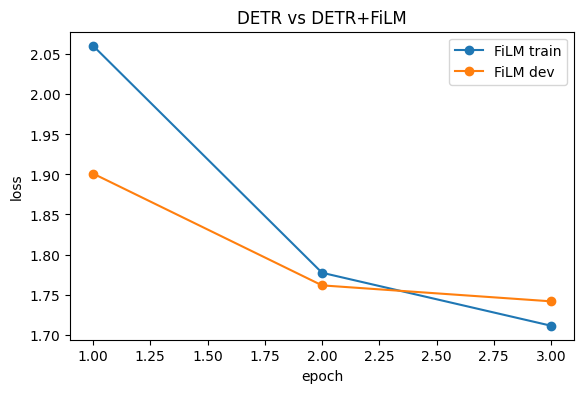

In [34]:
# training DETR + FiLM
assert CFG["epochs"] is not None
print(f"DETR+FiLM: {CFG['epochs']} epochs, batch {CFG['batch_size']}, seed {SEED}, film_lr {CFG['film_lr']}")

detr_film = build_detr_film()
state = fit("detr_film", detr_film, epochs=CFG["epochs"], use_beta=True)

hist_f = pd.DataFrame(state["history"])
print(hist_f.round(4).to_string(index=False))
print(f"\nBest dev loss {state['best_dev']:.4f} at epoch {int(hist_f.loc[hist_f.dev_loss.idxmin(), 'epoch'])}")
print("Total skipped (non-finite) steps:", int(hist_f.skipped_steps.sum()))

plt.figure(figsize=(6.5, 4))
plt.plot(hist_f.epoch, hist_f.train_loss, "o-", label="FiLM train")
plt.plot(hist_f.epoch, hist_f.dev_loss, "o-", label="FiLM dev")
bp = f"{RESULTS_DIR}/detr_baseline_history.csv"
if os.path.exists(bp):
    hb = pd.read_csv(bp)
    plt.plot(hb.epoch, hb.train_loss, "o--", label="baseline train")
    plt.plot(hb.epoch, hb.dev_loss, "o--", label="baseline dev")
plt.xlabel("epoch"); plt.ylabel("loss"); plt.legend(); plt.title("DETR vs DETR+FiLM"); plt.show()

In [35]:
# DETR+FiLM on the official val set, beta ablation, comparison vs baseline
detr_film = build_detr_film()
detr_film.load_state_dict(torch.load(f"{CKPT_DIR}/detr_film_best.pt", map_location=device))

res_film  = evaluate_detr_mode(detr_film, test_loader, "true");     save_results("detr_film", res_film)
res_swap  = evaluate_detr_mode(detr_film, test_loader, "swapped");  save_results("detr_film_swapped", res_swap)
res_const = evaluate_detr_mode(detr_film, test_loader, "constant"); save_results("detr_film_constant", res_const)
res_base  = load_results("detr_baseline")

keys = ["map", "map_50", "map_75", "map_small", "map_medium", "map_large",
        "mar_1", "mar_10", "mar_100", "mar_small", "mar_medium", "mar_large"]
tbl = pd.DataFrame({"DETR": res_base["overall"], "DETR+FiLM": res_film["overall"],
                    "FiLM, swapped beta": res_swap["overall"], "FiLM, constant beta": res_const["overall"]}).loc[keys]
tbl["FiLM - DETR"] = tbl["DETR+FiLM"] - tbl["DETR"]
print("Overall (official val set):\n", tbl.round(4).to_string())

pb = pd.DataFrame({"DETR": res_base["per_beta"]["map"], "DETR+FiLM": res_film["per_beta"]["map"],
                   "FiLM, swapped": res_swap["per_beta"]["map"], "FiLM, constant": res_const["per_beta"]["map"]})
pb["FiLM - DETR"] = pb["DETR+FiLM"] - pb["DETR"]
print("\nmAP by true fog density (beta):\n", pb.round(4).to_string())

pc = res_base["per_class"][["class", "n_gt", "AP"]].rename(columns={"AP": "DETR"}).merge(
     res_film["per_class"][["class", "AP"]].rename(columns={"AP": "DETR+FiLM"}), on="class")
pc["FiLM - DETR"] = pc["DETR+FiLM"] - pc["DETR"]
print("\nPer-class AP:\n", pc.round(4).to_string(index=False))
del detr_film; torch.cuda.empty_cache()

Loading weights:   0%|          | 0/530 [00:00<?, ?it/s]

evaluating (true):   0%|          | 0/375 [00:00<?, ?it/s]

evaluating (swapped):   0%|          | 0/375 [00:00<?, ?it/s]

evaluating (constant):   0%|          | 0/375 [00:00<?, ?it/s]

KeyboardInterrupt: 

**things to try?**
- smooth act func + SILU
- less film stages?


In [ ]:
# could try this --> FiLM v2 with Fourier features + SiLU ====
class FogFiLMV2(FogFiLM):
    def __init__(self, channels=(256, 512, 1024, 2048), emb=64, n_freq=4):
        super().__init__(channels, emb)
        self.n_freq = n_freq
        self.embed = nn.Sequential(nn.Linear(2 * n_freq, emb), nn.SiLU(),
                                   nn.Linear(emb, emb), nn.SiLU())
    def set_beta(self, beta_norm):
        b = beta_norm.reshape(-1, 1).float()
        freqs = (2.0 ** torch.arange(self.n_freq, device=b.device)) * float(np.pi)
        self.cond = self.embed(torch.cat([torch.sin(b * freqs), torch.cos(b * freqs)], dim=1))

**checkpoints**

In [ ]:
# checkpoints
for n in ["detr_baseline", "detr_film"]:
    p = f"{CKPT_DIR}/{n}_last.pt"
    if os.path.exists(p):
        st = torch.load(p, map_location="cpu", weights_only=False)["state"]
        print(f"{n}: {st['epoch']}/{CFG['epochs']} epochs done | best dev loss {st['best_dev']:.4f}")
    else:
        print(f"{n}: no checkpoint yet")

**computation cost**

In [ ]:
# compute cost
def count_params(model):
    return sum(p.numel() for p in model.parameters())

@torch.no_grad()
def count_flops(fwd):
    with FlopCounterMode(display=False) as fc:
        fwd()
    return fc.get_total_flops()          # counts a multiply-add as 2 FLOPs, so ~2x papers that report MACs

@torch.no_grad()
def measure_latency(fwd, n_warmup=30, n_iters=200):
    for _ in range(n_warmup):
        fwd()
    torch.cuda.synchronize(); torch.cuda.reset_peak_memory_stats()
    ts = []
    for _ in range(n_iters):
        s, e = torch.cuda.Event(enable_timing=True), torch.cuda.Event(enable_timing=True)
        s.record(); fwd(); e.record(); torch.cuda.synchronize()
        ts.append(s.elapsed_time(e))
    t = np.array(ts)
    return dict(mean_ms=t.mean(), median_ms=np.median(t), p95_ms=np.percentile(t, 95), std_ms=t.std(),
                fps=1000 / t.mean(), peak_mem_GB=torch.cuda.max_memory_allocated() / 1e9)

def profile_detr(name, model, use_beta):
    model.eval().to(device)
    batch = next(iter(test_loader))
    px, pm = batch["pixel_values"][:1].to(device), batch["pixel_mask"][:1].to(device)   # batch size 1
    if use_beta:
        model.model.backbone.beta = torch.tensor([0.5], device=device)
    fwd32 = lambda: model(pixel_values=px, pixel_mask=pm)
    def fwd():
        with torch.autocast("cuda", dtype=torch.float16, enabled=CFG["amp"]):
            return model(pixel_values=px, pixel_mask=pm)
    return dict(model=name, input=str(tuple(px.shape)), params_M=count_params(model) / 1e6,
                gflops=count_flops(fwd32) / 1e9, **measure_latency(fwd))

rows = []
for name, builder, use_beta in [("detr_baseline", build_detr_baseline, False),
                                ("detr_film", build_detr_film, True)]:
    m = builder()
    m.load_state_dict(torch.load(f"{CKPT_DIR}/{name}_best.pt", map_location=device))
    rows.append(profile_detr(name, m, use_beta))
    del m; torch.cuda.empty_cache()

compute_df = pd.DataFrame(rows)
compute_df.to_csv(f"{RESULTS_DIR}/compute_detr.csv", index=False)
print(compute_df.round(2).to_string(index=False))